# RadioSkySims Uses

Example flow of the RadioSkySim services. All services share a **common
reference date** (1 month ago) and a **24 h window with a 15 min step**.
Resources (solar flux, RINEX, TAP) are looked up locally (cache) and, if
needed, **online**; if nothing is found, the notebook raises a **clear
exception** and moves on to the next cells.

Each code cell uses `%%time` and reports the **wall time** at the end.

## 1. Reference parameters (all services)

Here we define the reference date (``REF_DATE`` = 1 month ago), the
simulation window (24 h, 15 min step) and the default observer (BINGO).
All services below use these parameters.

In [29]:
%%time
# ── Directory anchor: project root (CWD-independent) ──
# Ensures relative paths (e.g. Path("data")) resolve from the project root,
# regardless of where the Jupyter kernel started (notebooks/ or root).
import os

from radioskysims_core.paths import get_project_root

os.chdir(get_project_root())
print("cwd →", os.getcwd())

cwd → /share/lbarosi/RadioSkySimSuite
CPU times: user 1.35 ms, sys: 0 ns, total: 1.35 ms
Wall time: 1.07 ms


In [30]:
%%time
# ── Reference parameters shared by ALL services ──
from datetime import UTC, datetime, timedelta
from pathlib import Path

import numpy as np

# Reference date: 1 month ago (UTC).
REF_DATE = (datetime.now(UTC) - timedelta(days=30)).replace(microsecond=0)
print("Reference date (REF_DATE):", REF_DATE.isoformat())

# Simulation window: 24 h starting at REF_DATE, 15 min step.
# TimeRange.from_iso accepts naive ISO (UTC) — no timezone suffix.
from radioskysims_core.domain.common import FrequencyRange, TimeRange

_ISO_FMT = "%Y-%m-%dT%H:%M:%S"
TR = TimeRange.from_iso(
    REF_DATE.strftime(_ISO_FMT),
    (REF_DATE + timedelta(hours=24)).strftime(_ISO_FMT),
    60 * 15,
)
print(
    "TimeRange (24 h, 15 min):",
    TR.to_datetime64().shape[0],
    "instants | resolution:",
    TR.resolution_sec,
    "s",
)

FR = FrequencyRange(min_mhz=1000.0, max_mhz=1250.0, resolution_mhz=0.5)

# Reference observer (BINGO — Uirapuru/RN region).
from radioskysims_core.domain.common import Observer

OBSERVER = Observer(lat=-6.2391, lon=-38.9296, height=440.0, timeframe=TR)

# Local cache directories for downloads.
DATA_DIR = Path("data")
RINEX_DIR = DATA_DIR / "rinex"
SOLAR_DIR = DATA_DIR / "solar_flux"
for _d in (RINEX_DIR, SOLAR_DIR):
    _d.mkdir(parents=True, exist_ok=True)

Reference date (REF_DATE): 2026-10-08T20:53:23+00:00
TimeRange (24 h, 15 min): 97 instants | resolution: 900.0 s
CPU times: user 1.68 ms, sys: 0 ns, total: 1.68 ms
Wall time: 1.49 ms


In [31]:
%%time


# ── Resource access: local (cache) → online → raise (and continue) ──
def load_or_download(name, local=None, download=None):
    """Resolve a resource: use the local cache if present; otherwise download.

    - ``local``: callable returning the resource, or ``None``/``[]`` if absent.
    - ``download``: callable that fetches the resource online.
    - If neither local nor online resolves, raises a clear ``RuntimeError`` —
      the rest of the notebook continues from the next cells.
    """
    if local is not None:
        try:
            found = local()
            if found:
                print(f"[cache] {name}")
                return found
        except Exception:
            pass
    if download is None:
        raise RuntimeError(f"Resource '{name}' unavailable: no local file and no download.")
    print(f"[online] downloading {name} ...")
    try:
        return download()
    except Exception as exc:
        raise RuntimeError(
            f"Resource '{name}' unavailable: empty cache and online failed "
            f"({type(exc).__name__}: {exc})"
        ) from exc

CPU times: user 6 μs, sys: 0 ns, total: 6 μs
Wall time: 9.78 μs


### Composition root (dependency injection)

The facades (`SatelliteOrchestrator`, `LocalSourcesOrchestrator` and
`RadioSourcesOrchestrator`) receive their concrete factories — Skyfield
tracks, analytical PSD and repositories — through the **composition root**.
This is done **once** here, before using the services.

In [32]:
%%time
# ── Composition root: inject concrete factories into the facades (DI) ──
from radioskysims_sources.bootstrap.builders import configure_facade_defaults

configure_facade_defaults()
print("Facades configured (Skyfield tracks + analytical PSD + repositories).")

Facades configured (Skyfield tracks + analytical PSD + repositories).
CPU times: user 68 μs, sys: 2 μs, total: 70 μs
Wall time: 73.2 μs


## 2. Radio telescope & beam properties

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
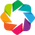

RadiotelescopeSpec(name='UIRAPURU Telescope', antennas=1 [BINGO Horn], loc=(-7.2116°, -35.9081°))
Antennas(n=1, names=['BINGO Horn'])
Available properties: FWHM, Gain, BeamPattern, effective_area, beam_width, frequency_range, num_channels, bandwidth, system_temperature
CPU times: user 103 ms, sys: 20 μs, total: 103 ms
Wall time: 102 ms


:Overlay
   .Tiles.I                                                                                                                         :Tiles   [x,y]
   .Points.UIRAPURU_Telescope_left_parenthesis_hyphen_minus_7_full_stop_2116_comma_hyphen_minus_35_full_stop_9081_right_parenthesis :Points   [x,y]

In [ ]:
%%time
import math

import holoviews as hv

hv.extension("bokeh")

from radioskysims import create_radiotelescope
from radioskysims_viz import save_plot

uirapuru = create_radiotelescope("default")
# Nicer __repr__ of RadiotelescopeSpec (aggregate)
print(uirapuru)
# Antennas: __repr__() lists the available properties
print(uirapuru.antennas)
# Interactive map (holoviews) with OSM tiles — zoom level 7, 800 px wide.
lat = float(uirapuru.observer.lat.to_value("deg"))
lon = float(uirapuru.observer.lon.to_value("deg"))
tiles = hv.element.tiles.OSM()  # .opts(zoom=7)
x, y = tiles.lon_lat_to_easting_northing(lon, lat)
point = hv.Points([(x, y)], label=f"{uirapuru.name} ({lat:.4f}, {lon:.4f})").opts(
    size=12, color="maroon"
)
map_plot = (tiles * point).opts(width=800, height=500)
map_plot
# Save as interactive HTML (OSM tiles are bokeh-only; matplotlib can't render them).
# save_plot(map_plot, "observer_osm_map")


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
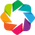

CPU times: user 496 ms, sys: 41.9 ms, total: 538 ms
Wall time: 537 ms


:Layout
   .Overlay.BINGO_Horn.I  :Overlay
      .Curve.BINGO_Horn   :Curve   [Frequency (MHz)]   (FWHM (deg))
      .Scatter.BINGO_Horn :Scatter   [Frequency (MHz)]   (FWHM (deg))
   .Overlay.BINGO_Horn.II :Overlay
      .Curve.BINGO_Horn   :Curve   [Frequency (MHz)]   (Gain (dBi))
      .Scatter.BINGO_Horn :Scatter   [Frequency (MHz)]   (Gain (dBi))
   .Overlay.I             :Overlay
      .Curve.BINGO_Horn_em_dash_1000_MHz :Curve   [Angle (deg)]   (Response (dB))
      .Curve.BINGO_Horn_em_dash_1050_MHz :Curve   [Angle (deg)]   (Response (dB))
      .Curve.BINGO_Horn_em_dash_1125_MHz :Curve   [Angle (deg)]   (Response (dB))
      .Curve.BINGO_Horn_em_dash_1175_MHz :Curve   [Angle (deg)]   (Response (dB))
      .Curve.BINGO_Horn_em_dash_1250_MHz :Curve   [Angle (deg)]   (Response (dB))

In [ ]:
%%time
# Beam properties panel: FWHM, Gain and Beam Pattern side by side (800 px wide).
fwhm = uirapuru.antennas.get_properties("FWHM").view().opts(title="FWHM", width=260, height=350)
gain = uirapuru.antennas.get_properties("Gain").view().opts(title="Gain", width=260, height=350)
pattern = (
    uirapuru.antennas.get_properties("BeamPattern")
    .view()
    .opts(title="Beam Pattern", width=260, height=350)
)
(fwhm + gain + pattern).cols(3)

## 3. Satellites

Uses `SatelliteManager` with `REF_DATE` (the reference date) and the 24 h
`TR` window. Requires PostgreSQL (`settings.toml`); if the local catalog is
unavailable, the error is shown and the notebook continues.

In [7]:
%%time
# Satellites via SatelliteOrchestrator (facade) — TLE at the reference date
import pandas as pd

from radioskysims_sources import SatelliteOrchestrator

CONSTELLATIONS = ["GPS", "GALILEO", "BEIDOU", "GLONASS"]

try:
    sat_orch = SatelliteOrchestrator.create_from_constellation(
        CONSTELLATIONS,
        epoch=REF_DATE,
    )
    sats = sat_orch.satellites
    tles = sat_orch.get_tle()
    print(f"{len(sats)} satellites found in the catalog (deduplicated by NORAD ID).")
    print(f"{len(tles)} TLEs selected — one per satellite, closest to {REF_DATE:%Y-%m-%d}.")

    # Table ordered by constellation and NORAD ID.
    table = (
        pd.DataFrame(
            [
                {
                    "constellation": s.constellation,
                    "norad_id": s.norad_id,
                    "name": s.name,
                    "prn": s.prn,
                    "sv": s.sv,
                    "tle_epoch": s.epoch.isoformat(),
                }
                for s in sats
            ]
        )
        .sort_values(["constellation", "norad_id"])
        .reset_index(drop=True)
    )
    display(table)
except Exception as exc:
    print("[warning] satellite catalog unavailable —", type(exc).__name__, str(exc)[:200])

138 satellites found in the catalog (deduplicated by NORAD ID).
138 TLEs selected — one per satellite, closest to 2026-10-08.


,constellation,norad_id,name,prn,sv,tle_epoch
0,BEIDOU,36828,BEIDOU-2 IGSO-1 (C06),6,C06,2026-10-24T13:46:15.118176+00:00
1,BEIDOU,37210,BEIDOU-2 G4 (C04),4,C04,2026-10-08T18:28:22.569024+00:00
2,BEIDOU,37256,BEIDOU-2 IGSO-2 (C07),7,C07,2026-10-08T09:39:43.274016+00:00
3,BEIDOU,37384,BEIDOU-2 IGSO-3 (C08),8,C08,2026-10-08T18:23:49.257312+00:00
4,BEIDOU,37763,BEIDOU-2 IGSO-4 (C09),9,C09,2026-10-08T16:28:22.829376+00:00
...,...,...,...,...,...,...
133,GPS,55268,GPS BIII-6 (PRN 28),28,G28,2026-10-09T22:39:59.999616+00:00
134,GPS,62339,GPS BIII-7 (PRN 01),1,G01,2026-10-09T02:33:46.516032+00:00
135,GPS,64202,GPS BIII-8 (PRN 21),21,G21,2026-10-26T04:59:49.744896+00:00
136,GPS,67588,GPS BIII-9 (PRN 20),20,G20,2026-10-08T20:52:41.471616+00:00


CPU times: user 4.84 s, sys: 51.3 ms, total: 4.89 s
Wall time: 4.94 s


We provide two helpers below: a **ground-track** helper (sub-satellite
latitude/longitude from the TLEs) and an **RA–Dec sky map**. The RA–Dec map is
built separately for the four main constellations, using a standard angular
cell resolution. Track density per unit area is computed with the haversine
metric and shown as a 2 × 2 heatmap panel.

salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sats_tracks_by_constellation.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sats_radec_density_2x2.png


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
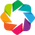

salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sats_signals.html
SatelliteAssembled(32 satélites [GPS BIIR-5 (PRN 22), GPS BIIR-8 (PRN 16), GPS BIIR-11 (PRN 19), GPS BIIR-13 (PRN 02), GPS BIIRM-1 (PRN 17), … (+27)]; tracks {'satellite': 32, 'time': 97, 'xyz': 3}, signals {'satellite': 128, 'freq': 501})
  por constelação: GPS=32


CPU times: user 50.9 s, sys: 258 ms, total: 51.1 s
Wall time: 48.7 s


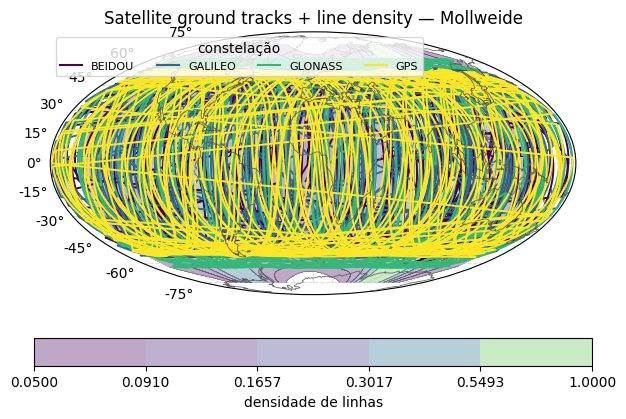

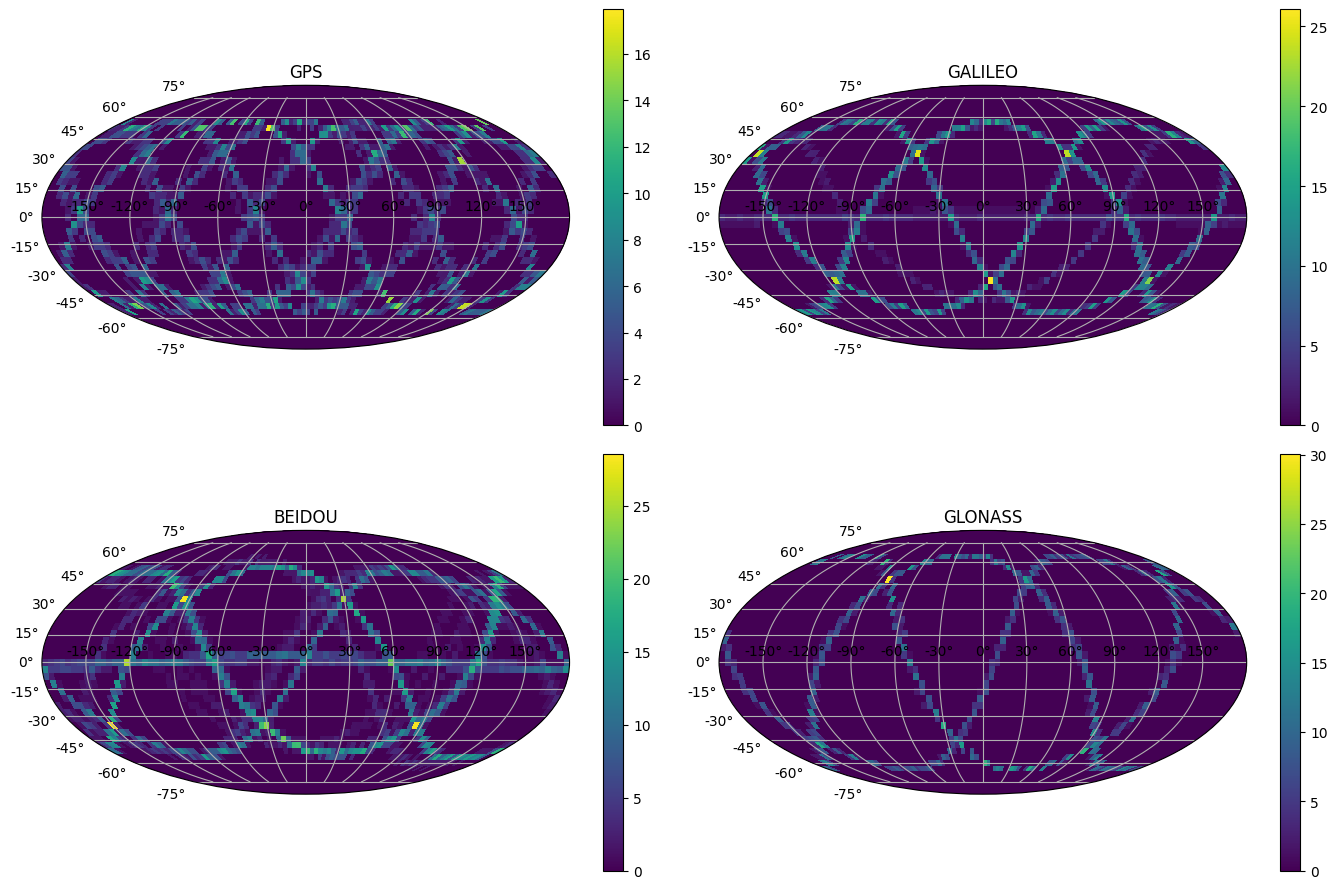

In [8]:
%%time
# build: assemble the SatelliteAssembled (tracks + signals) over the 24 h window
import matplotlib.pyplot as plt
import numpy as np

from radioskysims_viz import save_figure, save_plot


def ground_tracks(ds):
    """Sub-satellite points (lat, lon in degrees) from the tracks dataset.

    Rebuilds each ``EarthSatellite`` from the TLE lines stored in the dataset
    coords and converts its position to the Earth-fixed frame (ITRS).
    """
    from skyfield.api import EarthSatellite, load
    from skyfield.framelib import itrs

    ts = load.timescale()
    times = ts.tt_jd(np.asarray(ds.time.values, dtype=float))
    lats, lons = [], []
    for i in range(ds.sizes["satellite"]):
        sat = EarthSatellite(
            str(ds.tle_line1.values[i]).strip(),
            str(ds.tle_line2.values[i]).strip(),
            str(ds.names.values[i]),
            ts,
        )
        ecef = sat.at(times).frame_xyz(itrs).m
        lats.append(np.degrees(np.arctan2(ecef[2], np.sqrt(ecef[0] ** 2 + ecef[1] ** 2))))
        lons.append(np.degrees(np.arctan2(ecef[1], ecef[0])))
    return np.stack(lats), np.stack(lons)


def radec_density(ds, constellation, bins_ra=90, bins_dec=45):
    """RA/Dec sky-map density (tracks per unit solid angle) of a constellation."""
    if "constellation" in ds.coords:
        mask = np.array([str(c).upper() == constellation.upper() for c in ds.constellation.values])
        ds = ds.isel(satellite=mask)
    pos = np.asarray(ds["positions"].values, dtype=float)  # (sat, time, 3)
    x, y, z = pos[..., 0], pos[..., 1], pos[..., 2]
    r = np.sqrt(x * x + y * y + z * z)
    ra = (np.degrees(np.arctan2(y, x)) % 360).ravel()
    dec = np.degrees(np.arcsin(z / r)).ravel()
    # 1/cos(dec) weights compensate the projected area (density per unit area).
    weights = 1.0 / np.cos(np.radians(dec))
    h, ra_edges, dec_edges = np.histogram2d(
        ra,
        dec,
        bins=[bins_ra, bins_dec],
        range=[[0.0, 360.0], [-90.0, 90.0]],
        weights=weights,
    )
    return h, ra_edges, dec_edges


try:
    assembled = sat_orch.build(TR, FR)
    assembled  # friendly __repr__ (N satellites + dims)

    # Ground tracks (Mollweide): tracks by constellation + density contours
    fig = assembled.plot_tracks(by="constellation", contours=True)
    fig
    save_figure(fig, "sats_tracks_by_constellation")

    # RA–Dec sky-map density in Mollweide projection, one panel per constellation.
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), subplot_kw={"projection": "mollweide"})
    for ax, const in zip(axes.ravel(), CONSTELLATIONS, strict=False):
        h, ra_edges, dec_edges = radec_density(assembled.tracks, const)
        # Mollweide expects RA centered on 0° (radians, wrapped to [-π, π]).
        ra_c = (ra_edges - 180.0) * np.pi / 180.0
        dec_c = dec_edges * np.pi / 180.0
        im = ax.pcolormesh(ra_c, dec_c, h.T, cmap="viridis", shading="auto")
        ax.set_title(const)
        ax.grid(True)
        fig.colorbar(im, ax=ax)
    fig.tight_layout()
    save_figure(fig, "sats_radec_density_2x2")

    # PSD spectra × frequency — one curve per signal (L1/L2/L5)
    ov = assembled.plot_signals()
    ov
    save_plot(ov, "sats_signals")

    # Selection by constellation + signals of the selection
    gps = assembled.select_Constellation("GPS")
    print(gps.summary())
    um = assembled.select_Satellite(noradID=gps.norad_ids[0])
    um.plot_signals()
except Exception as exc:
    print(
        "[warning] satellite assembly/plot unavailable (Postgres?) —",
        type(exc).__name__,
        str(exc)[:200],
    )

### Satellites from RINEX (broadcast NAV)

Besides TLE (catalog), satellites can be created from broadcast ephemeris
(RINEX **NAV**) — real download (RBMC `pbcg`) with cache in `data/rinex/`.
`RinexSatelliteManager` follows the **same TLE flow**: creation →
`build_tracks(TR)` → views, using the same reference window `TR`.

In [9]:
# RINEX vs TLE validation and EIRP comparison.
#
# For the RINEX data we drop the ground-track plot and instead show, for the
# four constellations, the mean satellite range (altitude) and the difference
# between the nominal EIRP (from signals.json / get_constellation_signals) and
# the estimated EIRP derived from the link budget (C/N0 from the RINEX OBS +
# range from the NAV ephemeris). The legend shows the per-constellation mean of
# the differences and their equivalents in dBW.

[cache] RINEX NAV (pbcg): data/rinex/pbcg2811.26n
NAV: data/rinex/pbcg2811.26n
[cache] RINEX OBS (pbcg): data/rinex/pbcg2811.26d
OBS: data/rinex/pbcg2811.26d
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/rinex_satellites_mollweide.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/rinex_mean_range_per_constellation.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/rinex_satellites_signals.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/rinex_eirp_nominal_vs_estimated.png
Link budget (RINEX obs) — estimated EIRP per band:
  GPS L1 C/A @  1575.42 MHz: EIRP ~  25.21 dBW (n=32)
  GPS   L1C @  1575.42 MHz: EIRP ~  25.21 dBW (n=32)
  GPS   L2C @  1227.60 MHz: EIRP ~  23.05 dBW (n=32)
  GPS    L5 @  1176.45 MHz: EIRP ~  22.68 dBW (n=32)
signals.json fragment (estimated EIRP):
[
  {
    "constellation": "GPS",
    "eirp_dbw": 24.04,
    "rhcp": true,
    "signals": [
      {
        "name": "L5",
        "frequency": "1176.450000 MHz",
        "modulation":

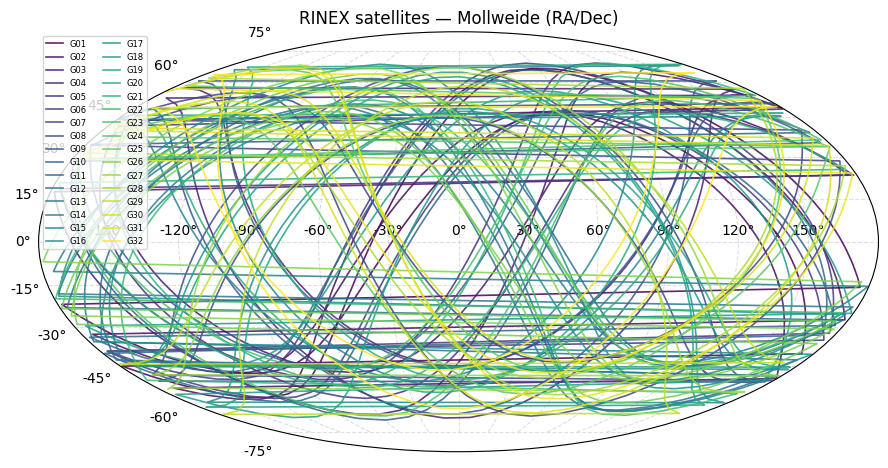

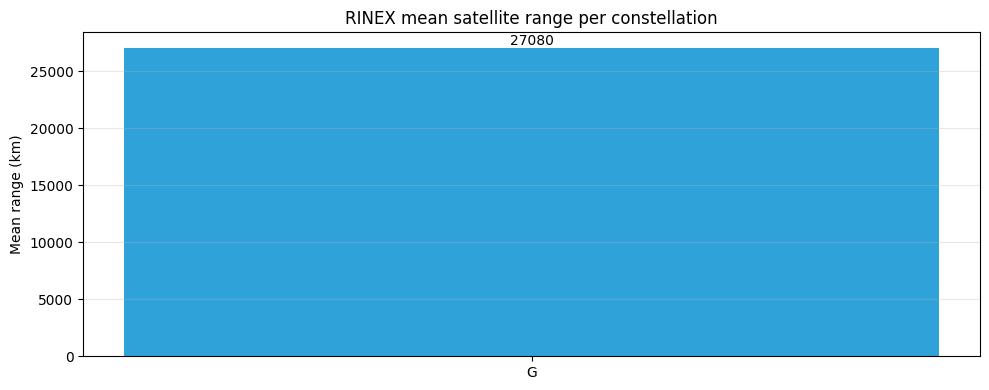

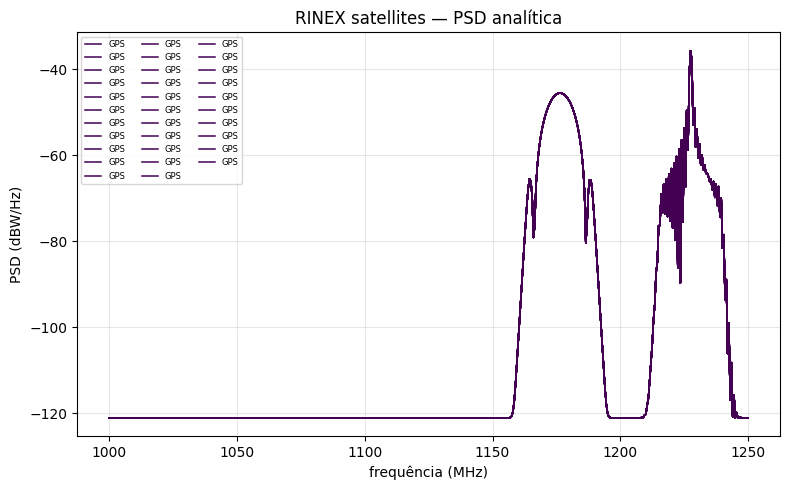

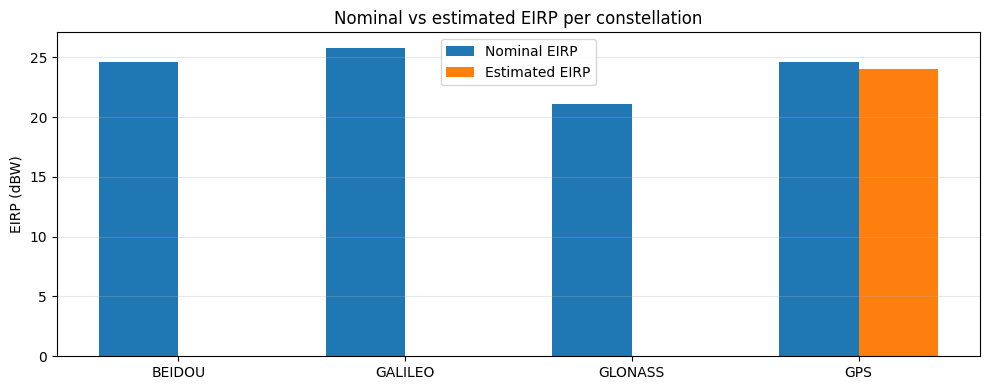

In [10]:
%%time
# Satellites from RINEX — NAV/OBS download + build(TR, FR) (same TLE flow)
import matplotlib.pyplot as plt
import numpy as np

from gnsstools4astro.application.services import RinexSatelliteManager
from radioskysims_viz import save_figure

STATION = "pbcg"  # RBMC station near BINGO


def _constellation_of(name: str) -> str:
    """Constellation tag from a satellite/SV name (first letter)."""
    return name[0].upper() if name else "?"


try:
    # 1) manager configured for the station/date
    rmgr = RinexSatelliteManager.for_station(STATION, ref_date=REF_DATE, cache_dir=RINEX_DIR)
    rmgr

    # 2) NAV download (local cache or online) — required for tracks/satellites
    nav_path = rmgr.download_nav()
    print("NAV:", nav_path)

    # 3) OBS download (local cache or online) — used by the link budget
    obs_path = rmgr.download_obs()
    if obs_path:
        print("OBS:", obs_path)
    else:
        print("[info] OBS unavailable for the date — link budget not evaluated")

    # 4) build(TR, FR) — like TLE: assemble tracks + signals (analytical PSD)
    rinex_assembled = rmgr.build(TR, FR)
    rinex_assembled  # __repr__: N satellites + dims

    rinex_assembled.summary()
    rmgr.list_satellites()  # loaded satellites (like get_tle() for TLE)
    rmgr.list_ephemerides()

    # 5) RA/Dec sky map (Mollweide) of the RINEX satellites.
    fig = rinex_assembled.plot_tracks()
    fig
    save_figure(fig, "rinex_satellites_mollweide")

    # 6) mean satellite range (altitude) per constellation — bar plot.
    tracks = rinex_assembled.tracks
    if "distance_km" in tracks:
        distance = tracks["distance_km"]
        mean_km = np.asarray(distance.mean("time").values, dtype=float)
        if "constellation" in tracks.coords:
            cons = [str(c) for c in tracks.constellation.values]
        else:
            cons = [_constellation_of(str(sv)) for sv in tracks.sv.values]

        fig, ax = plt.subplots(figsize=(10, 4))
        uniq = sorted(set(cons))
        means = [
            float(np.mean([m for m, c in zip(mean_km, cons, strict=False) if c == u])) for u in uniq
        ]
        bars = ax.bar(uniq, means, color="#30a2da")
        ax.bar_label(bars, fmt="%.0f")
        ax.set_ylabel("Mean range (km)")
        ax.set_title("RINEX mean satellite range per constellation")
        ax.grid(True, axis="y", alpha=0.3)
        fig.tight_layout()
        save_figure(fig, "rinex_mean_range_per_constellation")
    else:
        print("[info] no 'distance_km' in RINEX tracks — skipping range bar plot")

    # 7) signals — ANALYTICAL PSD (same TLE code): peaks at the carriers
    rinex_assembled.signals
    fig = rinex_assembled.plot_signals()
    fig
    save_figure(fig, "rinex_satellites_signals")

    # 8) link budget: C/N0 (obs) + range (nav) → estimated EIRP → signals.json
    if obs_path:
        import json as _json
        from gnsstools4astro.application.use_cases import EstimateLinkBudgetUseCase
        from gnsstools4astro.domain.constellations import get_constellation_signals

        signals_ref = get_constellation_signals()
        nominal_by_cons = {c.value: cs.eirp_dbw for c, cs in signals_ref.items()}

        estimates = rmgr.estimate_link_budget(obs_path)
        lb = EstimateLinkBudgetUseCase(signals_ref)
        summaries = lb.summarize(estimates)

        # Estimated EIRP per constellation (mean across bands).
        est_by_cons: dict[str, list[float]] = {}
        for s in summaries:
            est_by_cons.setdefault(s.constellation, []).append(s.eirp_dbw_mean)
        est_by_cons = {c: float(np.mean(v)) for c, v in est_by_cons.items()}

        cons = sorted(set(nominal_by_cons) | set(est_by_cons))
        nominal = [nominal_by_cons.get(c, np.nan) for c in cons]
        estimated = [est_by_cons.get(c, np.nan) for c in cons]

        fig, ax = plt.subplots(figsize=(10, 4))
        x = np.arange(len(cons))
        width = 0.35
        ax.bar(x - width / 2, nominal, width, label="Nominal EIRP")
        ax.bar(x + width / 2, estimated, width, label="Estimated EIRP")
        ax.set_xticks(x)
        ax.set_xticklabels(cons)
        ax.set_ylabel("EIRP (dBW)")
        ax.set_title("Nominal vs estimated EIRP per constellation")
        ax.legend()
        ax.grid(True, axis="y", alpha=0.3)
        fig.tight_layout()
        save_figure(fig, "rinex_eirp_nominal_vs_estimated")

        print("Link budget (RINEX obs) — estimated EIRP per band:")
        for s in summaries:
            print(
                f"  {s.constellation} {s.band_name:>5} @ {s.frequency_mhz:8.2f} MHz: "
                f"EIRP ~ {s.eirp_dbw_mean:6.2f} dBW (n={s.n_satellites})"
            )
        print("signals.json fragment (estimated EIRP):")
        print(_json.dumps(lb.to_signals_reference(estimates, base=signals_ref), indent=2))
except Exception as exc:
    print("[warning] RINEX unavailable (no local/online) —", type(exc).__name__, str(exc)[:200])

## 4. Local sources (Sun)

The Sun uses **real calibrated solar flux** from NoRP/Nobeyama (XDR format,
*absolute measurements*) with local cache in `data/solar_flux/` and a Skyfield
track at the reference observer.

[cache] solar flux (NoRP/Nobeyama)
solar flux: cache:solar_nro_20261008.nc
Sun — lat=-6.24°, lon=-38.93° | fluxo ≈ 7.652e+05 Jy @ 1000 MHz
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sun_altaz_flux_sfu.png
CPU times: user 442 ms, sys: 5.01 ms, total: 447 ms
Wall time: 312 ms


PosixPath('/share/lbarosi/RadioSkySimSuite/notebooks/plots/sun_altaz_flux_sfu.png')

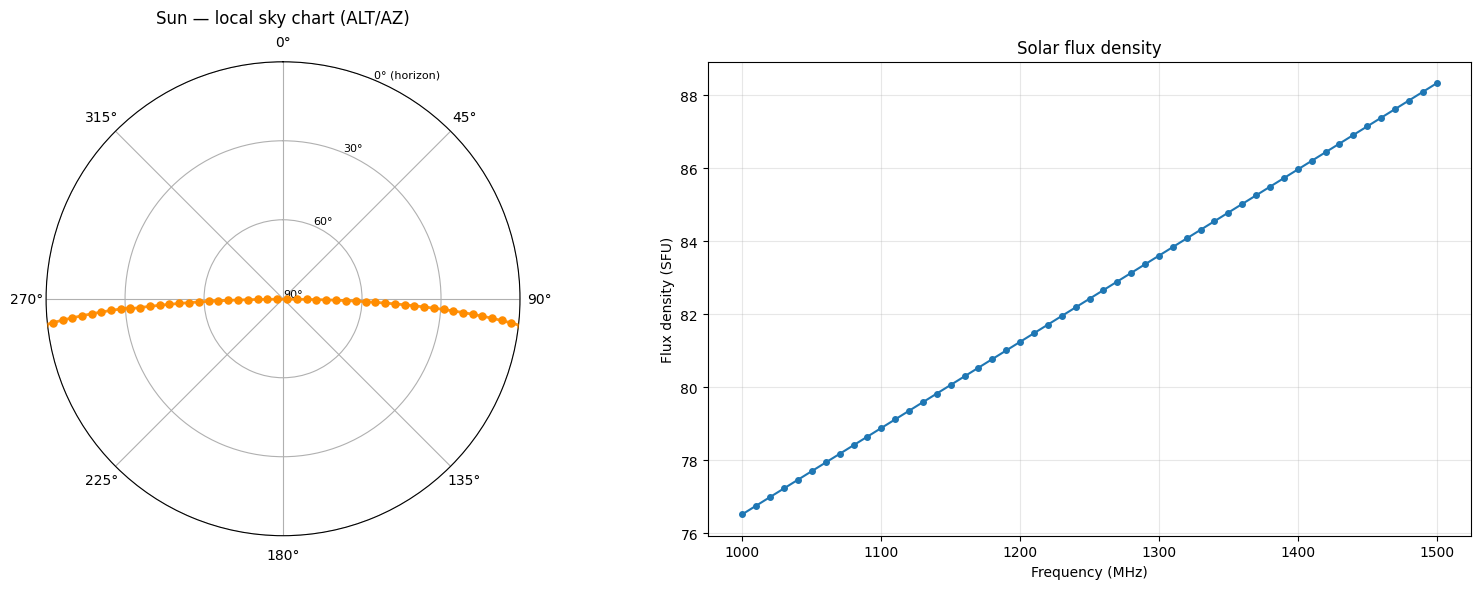

In [11]:
%%time
# Sun — REAL solar flux (NoRP/Nobeyama) with local cache + Skyfield track
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from radioskysims_viz import save_figure
from radioskysims_sources import LocalSourcesOrchestrator
from radioskysims_sources.domain.localsources import SolarFlux
from radioskysims_sources.infrastructure.external.nro_solar_flux_downloader import (
    NroSolarFluxDownloader,
)

SOLAR_NC = SOLAR_DIR / f"solar_nro_{REF_DATE:%Y%m%d}.nc"


def _solar_from_cache(nc: Path):
    ds = xr.open_dataset(nc)
    t = ds["time"].values.astype("datetime64[ns]")
    return SolarFlux(
        start_utc=pd.Timestamp(np.datetime64(t[0], "s")).to_pydatetime(),
        end_utc=pd.Timestamp(np.datetime64(t[-1], "s")).to_pydatetime(),
        dataset=ds,
        source_url=f"cache:{nc.name}",
    )


# Real solar flux (cache → online); on failure, fall back to a quiet Sun.
try:
    solar_flux = load_or_download(
        name="solar flux (NoRP/Nobeyama)",
        local=lambda: _solar_from_cache(SOLAR_NC) if SOLAR_NC.exists() else None,
        download=lambda: NroSolarFluxDownloader(timeout_sec=60).fetch(
            center_utc=REF_DATE, window_hours=24
        ),
    )
    if not SOLAR_NC.exists():
        try:
            solar_flux.dataset.to_netcdf(SOLAR_NC)
            print("  cache saved:", SOLAR_NC)
        except Exception as _exc:
            print("  [warning] could not save solar-flux cache:", _exc)
    print("solar flux:", solar_flux.source_url)
except Exception as exc:
    print(
        "[warning] solar flux unavailable online — using quiet Sun:",
        type(exc).__name__,
        str(exc)[:200],
    )
    solar_flux = None

# Sun with the real flux (or quiet Sun) + track at the reference observer
sun = LocalSourcesOrchestrator.create_sun(observer=OBSERVER, time_range=TR, flux=solar_flux)
print(sun.summary())

# Polar ALT/AZ sky chart + solar flux density in SFU, side by side.
az = sun.track.dataset["az_rad"].values.astype(float)
el = sun.track.dataset["el_rad"].values.astype(float)
zenith = np.pi / 2.0 - el  # 0 at zenith, π/2 at the horizon

fd = sun.flux_density()
freqs_mhz = fd.freqs_mhz
flux_sfu = fd.total / 1e4  # 1 SFU = 10^4 Jy

fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(121, projection="polar")
ax1.set_theta_zero_location("N")
ax1.set_theta_direction(-1)
ax1.set_rlim(0.0, np.pi / 2.0)
ax1.set_rticks([0.0, np.pi / 6.0, np.pi / 3.0, np.pi / 2.0])
ax1.set_yticklabels(["90°", "60°", "30°", "0° (horizon)"], fontsize=8)
ax1.plot(az, zenith, "-", color="#ff8c00", lw=2.0, alpha=0.9)
ax1.scatter(az, zenith, s=26, color="#ff8c00", zorder=5)
ax1.set_title("Sun — local sky chart (ALT/AZ)", va="bottom")

ax2 = fig.add_subplot(122)
ax2.plot(freqs_mhz, flux_sfu, marker="o", ms=4)
ax2.set_xlabel("Frequency (MHz)")
ax2.set_ylabel("Flux density (SFU)")
ax2.set_title("Solar flux density")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
save_figure(fig, "sun_altaz_flux_sfu")

## 5. Radio sources

`RadioSourcesOrchestrator` loads the **real catalog** (`radio_sources` table,
re-ingested via TAP NVSS+SPECFIND) or, without a database, falls back to a
simulated catalog. You can also ingest **real NVSS + SPECFIND via TAP/ADQL
(VizieR)** on the fly (network required).

**Spectral index (α):** sources without a SPECFIND measurement use a
**synchrotron prior** (deterministic per source) — the real catalog now has
varying α instead of all 0.7.

spectral indices (α): 323 unique | 0.0 - 1.47


,id,ra_deg,dec_deg,nu0_mhz,s0_jy,alpha,flux_1400mhz_jy
0,120022+024737,180.094208,2.793833,1400.0,0.1002,1.232789,0.1002
1,120023-010559,180.098458,-1.099806,1400.0,0.1539,0.826001,0.1539
2,120045+040636,180.188750,4.110056,1400.0,0.3521,0.222758,0.3521
3,120123+002829,180.346875,0.474833,1400.0,0.3784,0.391386,0.3784
4,120205+024851,180.523250,2.814167,1400.0,0.2624,0.527034,0.2624
...,...,...,...,...,...,...,...
318,131920-005605,199.834750,-0.934861,1400.0,0.1704,1.084005,0.1704
319,131923-005442,199.845875,-0.911861,1400.0,0.1657,0.453941,0.1657
320,131931+033336,199.879250,3.560028,1400.0,0.1918,0.741824,0.1918
321,131938-004940,199.911375,-0.828028,1400.0,1.4689,0.636874,1.4689


salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/radio_sources_mollweide.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/radio_sources_flux_density.png
12 sources with S0 >= 1 Jy
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/radio_sources_bright_flux.png


Servidor TAP https://tapvizier.cds.unistra.fr/TAPVizieR/tap falhou (TimeoutError: [Errno 110] Connection timed out); tentando próximo da lista.
Servidor TAP https://tapvizier.u-strasbg.fr/TAPVizieR/tap falhou (TimeoutError: [Errno 110] Connection timed out); tentando próximo da lista.


[warning] TAP unavailable (network required to reach the VizieR TAP servers) — RuntimeError: Todos os servidores TAP VizieR falharam (2 tentativas). Último erro: TimeoutError: [Errno 110] Connection timed out
CPU times: user 1.28 s, sys: 14 ms, total: 1.3 s
Wall time: 4min 31s


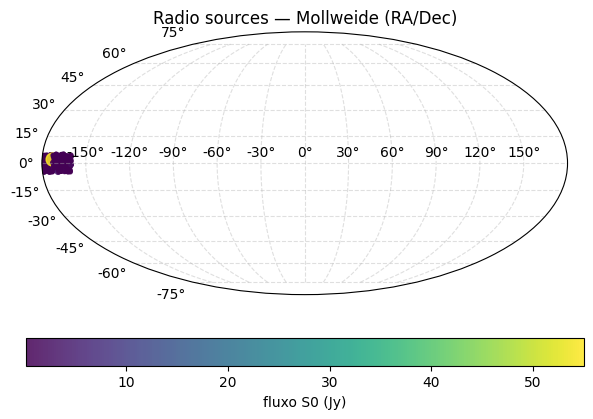

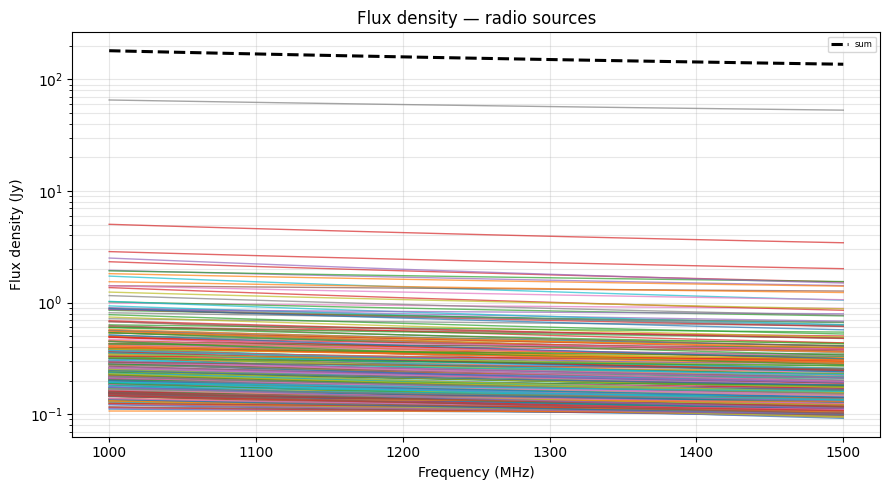

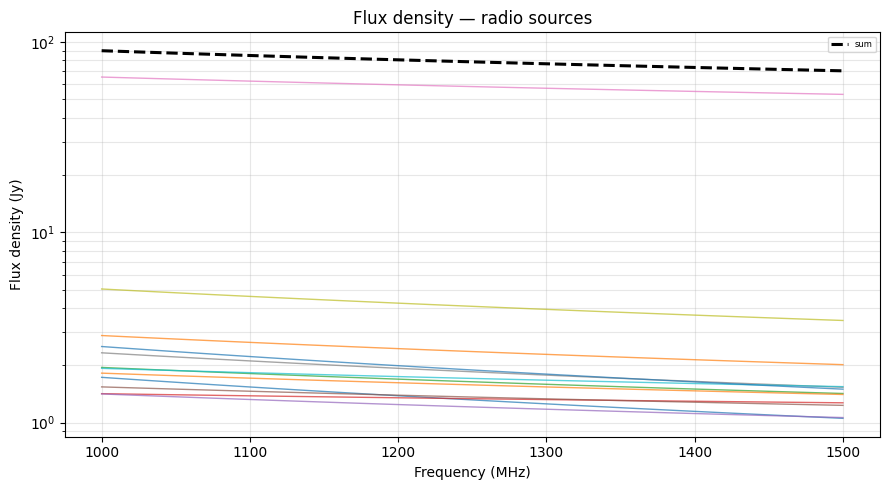

In [12]:
%%time
# RadioSources: real catalog (radio_sources table) — re-ingested via TAP
import matplotlib.pyplot as plt

from radioskysims_viz import save_figure
from radioskysims_sources import RadioSourcesOrchestrator

# Load from the database (323 real NVSS sources, varying α). Demo alternative:
#   radiosources = RadioSourcesOrchestrator.simulated(n_sources=40, seed=7)
radiosources = RadioSourcesOrchestrator.from_db()
radiosources  # friendly __repr__ (N sources)

# Properties table (fluxes in Jy, frequencies in MHz).
df = radiosources.list_properties()
print(
    "spectral indices (α):",
    df["alpha"].nunique(),
    "unique |",
    round(df["alpha"].min(), 3),
    "-",
    round(df["alpha"].max(), 3),
)
display(df)

fig = radiosources.view_mollweide()
fig
save_figure(fig, "radio_sources_mollweide")


def flux_plot(flux_density, *, title=None):
    """Flux-density curves: linear MHz x-axis, logarithmic Jy y-axis."""
    fig, ax = plt.subplots(figsize=(9, 5))
    for sid, f in flux_density.flux_by_source.items():
        ax.plot(flux_density.freqs_mhz, f, lw=1.0, alpha=0.7)
    ax.plot(flux_density.freqs_mhz, flux_density.total, color="k", lw=2.2, ls="--", label="sum")
    ax.set_yscale("log")
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Flux density (Jy)")
    ax.set_title(title or "Flux density — radio sources")
    ax.grid(True, which="both", alpha=0.3)
    if flux_density.flux_by_source:
        ax.legend(loc="best", fontsize=6, ncol=2)
    fig.tight_layout()
    return fig


fig = flux_plot(radiosources.flux_density())
fig
save_figure(fig, "radio_sources_flux_density")

# Selection by criteria + flux of the selection
bright = radiosources.select(min_flux_jy=1.0)
print(f"{len(bright)} sources with S0 >= 1 Jy")
fig = flux_plot(bright.flux_density())
fig
save_figure(fig, "radio_sources_bright_flux")

# ── Real TAP (VizieR): re-ingest NVSS + SPECFIND over a sky window ──
# Sources without SPECFIND use a synchrotron α prior (not all 0.7).
try:
    tap = RadioSourcesOrchestrator.from_tap(
        ra_min_deg=180.0,
        ra_max_deg=200.0,
        dec_min_deg=-5.0,
        dec_max_deg=5.0,
        smin_jy=0.1,
    )
    print(f"{len(tap)} real NVSS sources (TAP VizieR)")
    tap_df = tap.list_properties()
    print("  real α:", tap_df["alpha"].round(3).nunique(), "unique")
    display(tap_df)
    fig = flux_plot(tap.flux_density())
    fig
    save_figure(fig, "radio_sources_tap_flux")
except Exception as exc:
    print(
        "[warning] TAP unavailable (network required to reach the VizieR TAP "
        f"servers) — {type(exc).__name__}: {str(exc)[:200]}"
    )

## Next steps

This notebook covers the radio telescope, satellites (TLE/RINEX), the Sun and
radio sources. For the other RadioSkySim flows, see:

- `01_maps.ipynb` — sky maps (SkyMap).
- `02_sims.ipynb` — TOD simulation.
- `03_waterfall.ipynb` — waterfall (channel × time).